# 01 — Logistics & Customer Satisfaction (EDA)

**CRISP-DM phase:** Data Understanding

**Business questions**
1. How did the business evolve over time?
2. How reliable are deliveries?
3. Do late deliveries cause bad reviews — and is the effect real or just a regional artefact?
4. Where (which states) are the problems concentrated?
5. Why are orders late: the seller or the carrier?
6. Do customers answer the satisfaction survey before the parcel arrives?

**Data:** `data/processed/orders.parquet` — one row per delivered order, built by `src/build_datasets.py` from `sql/05_order_dataset.sql`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

# Works whether the notebook is run from the project root or from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# One consistent palette: grey = context, red = problem, blue = neutral highlight
GREY, RED, BLUE, DARK = "#B0B7BF", "#D1495B", "#2E86AB", "#2B2D42"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "font.size": 10,
})


def save(fig, name):
    """Save a figure for the README / dashboard."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


orders = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "orders.parquet")

# Complete months only for time trends (2016 = ramp-up, Sep/Oct 2018 = cut-off)
complete = orders[(orders["purchase_ts"] >= "2017-01-01") & (orders["purchase_ts"] < "2018-09-01")]

# Orders that have a review (646 delivered orders have none)
reviewed = orders.dropna(subset=["review_score"]).copy()

print(f"{len(orders):,} delivered orders")
print(f"{len(complete):,} in complete months (Jan 2017 – Aug 2018)")
print(f"{len(reviewed):,} with a review")

96,470 delivered orders
96,203 in complete months (Jan 2017 – Aug 2018)
95,824 with a review


## 1. How did the business evolve?

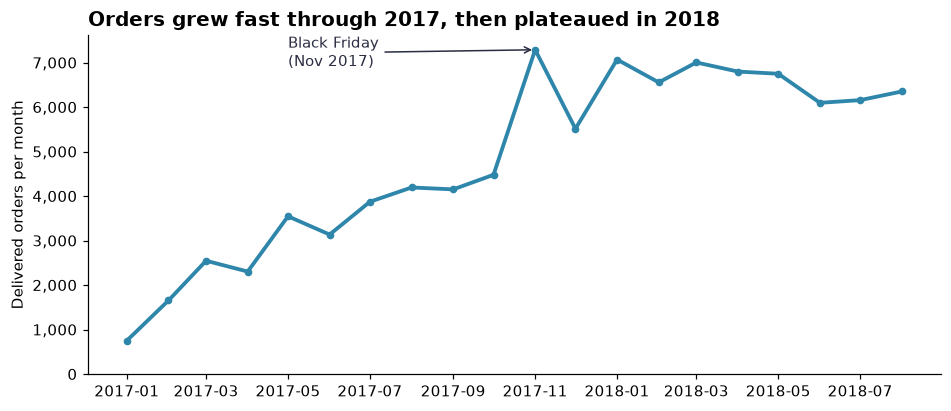

Revenue Jan–Aug 2018 vs Jan–Aug 2017: +141%


In [2]:
monthly = complete.groupby("purchase_month").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
)
x = pd.to_datetime(monthly.index)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, monthly["orders"], color=BLUE, lw=2.5, marker="o", ms=4)
ax.annotate(
    "Black Friday\n(Nov 2017)",
    xy=(pd.Timestamp("2017-11-01"), monthly.loc["2017-11", "orders"]),
    xytext=(pd.Timestamp("2017-05-01"), monthly["orders"].max() * 0.95),
    arrowprops=dict(arrowstyle="->", color=DARK),
    color=DARK,
)
ax.set_title("Orders grew fast through 2017, then plateaued in 2018")
ax.set_ylabel("Delivered orders per month")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0)
save(fig, "01_monthly_orders")
plt.show()

h1_2017 = monthly.loc["2017-01":"2017-08", "revenue"].sum()
h1_2018 = monthly.loc["2018-01":"2018-08", "revenue"].sum()
print(f"Revenue Jan–Aug 2018 vs Jan–Aug 2017: {h1_2018 / h1_2017 - 1:+.0%}")

## 2. How reliable are deliveries?

`delay_days` = delivery date − promised date. Negative means the order arrived **early**.

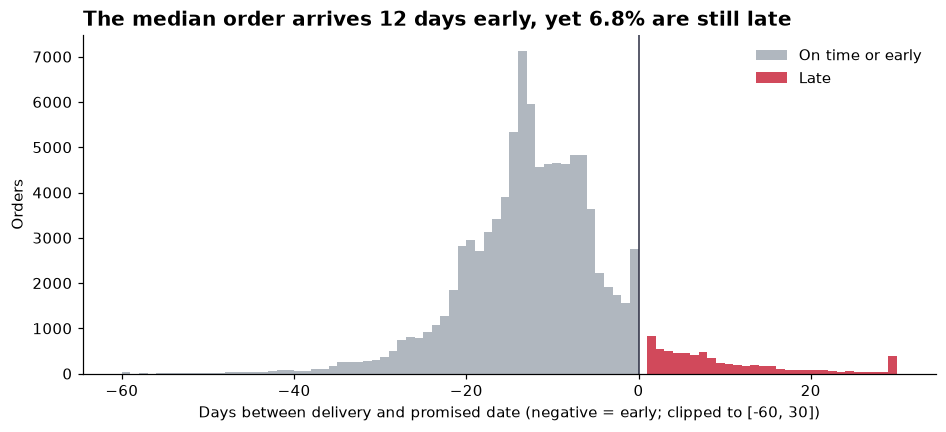

Average days to deliver: 12.6
Average days promised:   23.7
Late orders:             6.8%


In [3]:
d = orders["delay_days"].clip(-60, 30)  # clip extreme values so the chart stays readable

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d[d <= 0], bins=range(-60, 1), color=GREY, label="On time or early")
ax.hist(d[d > 0], bins=range(0, 31), color=RED, label="Late")
ax.axvline(0, color=DARK, lw=1)
ax.set_title(
    f"The median order arrives {-orders['delay_days'].median():.0f} days early, "
    f"yet {orders['is_late'].mean():.1%} are still late"
)
ax.set_xlabel("Days between delivery and promised date (negative = early; clipped to [-60, 30])")
ax.set_ylabel("Orders")
ax.legend(frameon=False)
save(fig, "02_delay_distribution")
plt.show()

print(f"Average days to deliver: {orders['days_to_deliver'].mean():.1f}")
print(f"Average days promised:   {orders['days_promised'].mean():.1f}")
print(f"Late orders:             {orders['is_late'].mean():.1%}")

## 3. Do late deliveries cause bad reviews?

A **bad review** is a score of 1 or 2 stars.

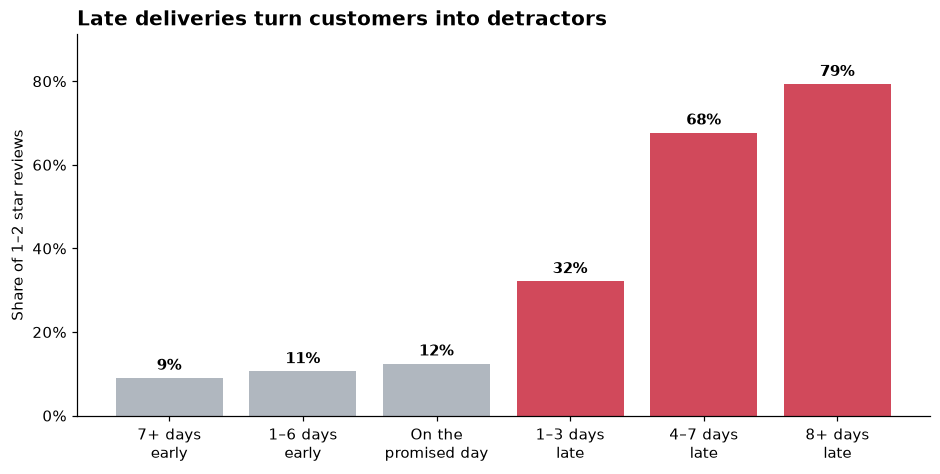

,orders,avg_review,bad_review_rate
delivery_bucket,,,
7+ days\nearly,75744,4.313,0.09
1–6 days\nearly,12419,4.179,0.106
On the\npromised day,1280,4.034,0.124
1–3 days\nlate,1852,3.291,0.321
4–7 days\nlate,1748,2.103,0.677
8+ days\nlate,2781,1.696,0.793


In [4]:
bins = [-np.inf, -7, -1, 0, 3, 7, np.inf]
labels = ["7+ days\nearly", "1–6 days\nearly", "On the\npromised day",
          "1–3 days\nlate", "4–7 days\nlate", "8+ days\nlate"]
# pd.cut puts each delay into a bucket: (-inf, -7], (-7, -1], (-1, 0], (0, 3], ...
reviewed["delivery_bucket"] = pd.cut(reviewed["delay_days"], bins=bins, labels=labels)

by_bucket = reviewed.groupby("delivery_bucket", observed=True).agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    bad_review_rate=("is_bad_review", "mean"),
)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(by_bucket.index.astype(str), by_bucket["bad_review_rate"],
              color=[GREY] * 3 + [RED] * 3)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in by_bucket["bad_review_rate"]],
             padding=3, fontweight="bold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, by_bucket["bad_review_rate"].max() * 1.15)
ax.set_ylabel("Share of 1–2 star reviews")
ax.set_title("Late deliveries turn customers into detractors")
save(fig, "03_bad_reviews_by_delay")
plt.show()

by_bucket.round(3)

### 3.1 Is the difference statistically significant?

- **Chi-square test**: are "late" and "bad review" independent? A tiny p-value says no.
- **Relative risk (RR)**: how many times more likely a bad review is when the order is late, with a 95% confidence interval.
- **Mann-Whitney U**: do late orders get lower scores overall? (Non-parametric — review scores are not normally distributed.)

In [5]:
late = reviewed[reviewed["is_late"] == True]
on_time = reviewed[reviewed["is_late"] == False]

# Chi-square test on the 2x2 table (late yes/no × bad review yes/no)
table = pd.crosstab(reviewed["is_late"], reviewed["is_bad_review"])
chi2, p_chi2, _, _ = stats.chi2_contingency(table)

# Relative risk with a 95% CI (log method)
a, n1 = late["is_bad_review"].sum(), len(late)
c, n2 = on_time["is_bad_review"].sum(), len(on_time)
rr = (a / n1) / (c / n2)
se_log_rr = np.sqrt(1 / a - 1 / n1 + 1 / c - 1 / n2)
ci_low, ci_high = np.exp(np.log(rr) + np.array([-1.96, 1.96]) * se_log_rr)

# Mann-Whitney: are late-order scores systematically LOWER?
_, p_mw = stats.mannwhitneyu(late["review_score"], on_time["review_score"], alternative="less")

print(table, "\n")
print(f"Bad-review rate — late: {a / n1:.1%}   on time: {c / n2:.1%}")
print(f"Relative risk: {rr:.1f}x  (95% CI {ci_low:.2f}–{ci_high:.2f})")
# p-values this small underflow to 0.0 in floating point, so report them as < 0.001
fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
print(f"Chi-square = {chi2:,.0f}, {fmt_p(p_chi2)}")
print(f"Mann-Whitney U (late < on time), {fmt_p(p_mw)}")

is_bad_review  False  True 
is_late                    
False          81154   8289
True            2398   3983 

Bad-review rate — late: 62.4%   on time: 9.3%
Relative risk: 6.7x  (95% CI 6.55–6.93)
Chi-square = 15,064, p < 0.001
Mann-Whitney U (late < on time), p < 0.001


### 3.2 Is it just a regional effect? (confounding check)

Northern/Northeastern states have **both** more delays **and** maybe more demanding customers. If region explained everything, the late-vs-on-time gap would vanish *within* each state. Two checks:
1. Compare bad-review rates for late vs on-time orders **inside each state**.
2. A **logistic regression** of `bad review ~ late + state`, which estimates the effect of lateness *holding the state constant*.

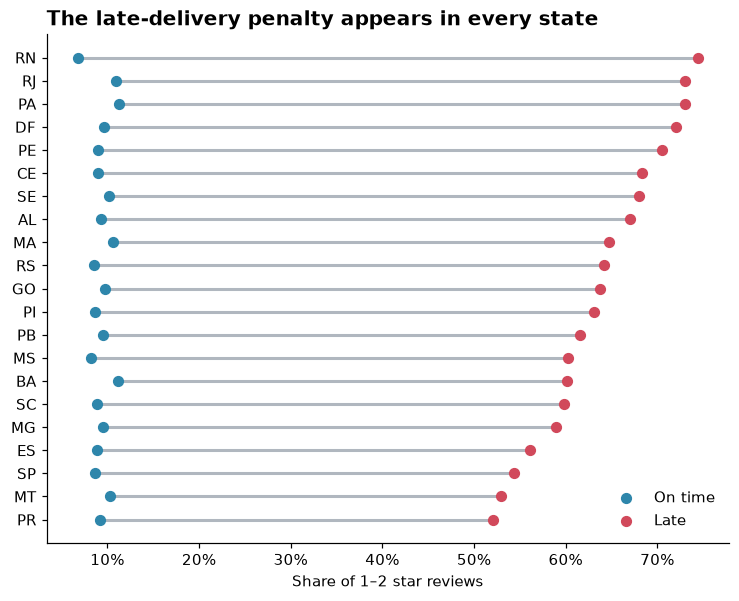

Late orders have a higher bad-review rate in 21 of 21 states


In [6]:
rate = reviewed.groupby(["customer_state", "is_late"])["is_bad_review"].mean().unstack()
count = reviewed.groupby(["customer_state", "is_late"]).size().unstack()
rate = rate[count[True] >= 30]                       # keep states with 30+ late orders
rate = rate.rename(columns={False: "on_time", True: "late"}).sort_values("late")

fig, ax = plt.subplots(figsize=(8, 6))
ax.hlines(rate.index, rate["on_time"], rate["late"], color=GREY, lw=2)
ax.scatter(rate["on_time"], rate.index, color=BLUE, s=40, label="On time", zorder=3)
ax.scatter(rate["late"], rate.index, color=RED, s=40, label="Late", zorder=3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of 1–2 star reviews")
ax.set_title("The late-delivery penalty appears in every state")
ax.legend(frameon=False, loc="lower right")
save(fig, "04_bad_reviews_by_state_late_vs_on_time")
plt.show()

print(f"Late orders have a higher bad-review rate in {(rate['late'] > rate['on_time']).sum()} of {len(rate)} states")

In [7]:
model_df = reviewed.assign(
    bad=reviewed["is_bad_review"].astype(int),
    late=reviewed["is_late"].astype(int),
)
logit = smf.logit("bad ~ late + C(customer_state)", data=model_df).fit(disp=False)

odds_ratio = np.exp(logit.params["late"])
or_low, or_high = np.exp(logit.conf_int().loc["late"])
print(f"Odds ratio for 'late', controlling for state: {odds_ratio:.1f} (95% CI {or_low:.1f}–{or_high:.1f})")

# Odds ratio ≠ relative risk. RR compares probabilities (62% / 9% ≈ 6.7);
# OR compares odds (0.62/0.38 vs 0.09/0.91). When the outcome is common (62%),
# the OR is much larger than the RR, so 15.6 and 6.7 do not contradict each other.

Odds ratio for 'late', controlling for state: 15.6 (95% CI 14.7–16.5)


## 4. Where are the problems concentrated?

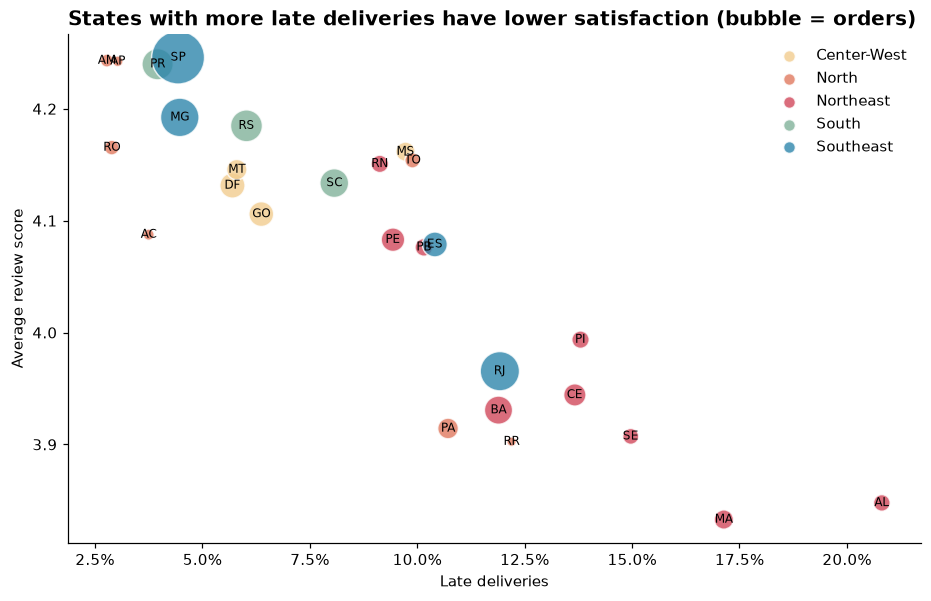

Correlation between state late rate and average review: -0.88


,orders,late_rate,days_to_deliver,avg_review,region
customer_state,,,,,
AL,394,0.208,24.457,3.848,Northeast
MA,712,0.171,21.442,3.833,Northeast
SE,334,0.15,21.439,3.907,Northeast
PI,471,0.138,19.494,3.994,Northeast
CE,1273,0.137,21.205,3.944,Northeast
RR,41,0.122,29.388,3.902,North
RJ,12211,0.119,15.242,3.965,Southeast
BA,3229,0.119,19.246,3.931,Northeast


In [8]:
REGION = {
    **dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "North"),
    **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Northeast"),
    **dict.fromkeys(["DF", "GO", "MT", "MS"], "Center-West"),
    **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Southeast"),
    **dict.fromkeys(["PR", "RS", "SC"], "South"),
}
REGION_COLOR = {"North": "#E07A5F", "Northeast": RED, "Center-West": "#F2CC8F",
                "Southeast": BLUE, "South": "#81B29A"}

by_state = reviewed.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    days_to_deliver=("days_to_deliver", "mean"),
    avg_review=("review_score", "mean"),
)
by_state["region"] = by_state.index.map(REGION)

fig, ax = plt.subplots(figsize=(10, 6))
for region, grp in by_state.groupby("region"):
    ax.scatter(grp["late_rate"], grp["avg_review"], s=np.sqrt(grp["orders"]) * 6,
               color=REGION_COLOR[region], alpha=0.8, label=region, edgecolor="white")
for state, row in by_state.iterrows():
    ax.annotate(state, (row["late_rate"], row["avg_review"]), fontsize=8,
                ha="center", va="center")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Late deliveries")
ax.set_ylabel("Average review score")
ax.set_title("States with more late deliveries have lower satisfaction (bubble = orders)")
legend = ax.legend(frameon=False)
for handle in legend.legend_handles:   # same marker size for every region in the legend
    handle.set_sizes([60])
save(fig, "05_states_late_vs_review")
plt.show()

corr = by_state["late_rate"].corr(by_state["avg_review"])
print(f"Correlation between state late rate and average review: {corr:.2f}")
by_state.sort_values("late_rate", ascending=False).head(8).round(3)

## 5. Why are orders late: the seller or the carrier?

Delivery time splits into two stages:
- **Seller stage**: purchase → handed to the carrier (`carrier_ts`)
- **Carrier stage**: handed to the carrier → delivered to the customer

Data quality: some orders have a carrier date *before* the purchase or *after* the delivery. These are recording errors, so we drop them and report how many.

Dropped 188 orders with impossible dates (0.2%)


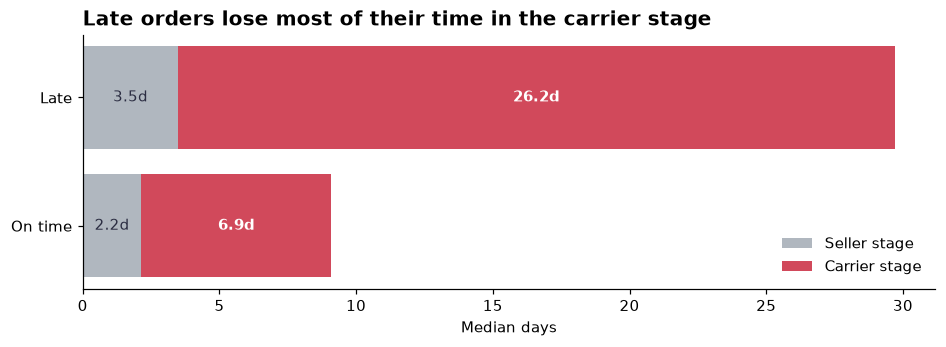

,seller_days,carrier_days
On time,2.2,6.9
Late,3.5,26.2


In [9]:
stages = orders.dropna(subset=["carrier_ts"]).copy()
stages["seller_days"] = (stages["carrier_ts"] - stages["purchase_ts"]).dt.total_seconds() / 86400
stages["carrier_days"] = (stages["delivered_ts"] - stages["carrier_ts"]).dt.total_seconds() / 86400

valid = (stages["seller_days"] >= 0) & (stages["carrier_days"] >= 0)
print(f"Dropped {(~valid).sum():,} orders with impossible dates ({(~valid).mean():.1%})")
stages = stages[valid]

stage_medians = stages.groupby("is_late")[["seller_days", "carrier_days"]].median()
stage_medians.index = ["On time", "Late"]

fig, ax = plt.subplots(figsize=(10, 3))
ax.barh(stage_medians.index, stage_medians["seller_days"], color=GREY, label="Seller stage")
ax.barh(stage_medians.index, stage_medians["carrier_days"], left=stage_medians["seller_days"],
        color=RED, label="Carrier stage")
for i, (s, c) in enumerate(stage_medians.values):
    ax.text(s / 2, i, f"{s:.1f}d", ha="center", va="center", color=DARK)
    ax.text(s + c / 2, i, f"{c:.1f}d", ha="center", va="center", color="white", fontweight="bold")
ax.set_xlabel("Median days")
ax.set_title("Late orders lose most of their time in the carrier stage")
ax.legend(frameon=False, loc="lower right")
save(fig, "06_delay_stages")
plt.show()

stage_medians.round(1)

In [10]:
same_state = orders.groupby("same_state").agg(
    orders=("order_id", "count"),
    median_days=("days_to_deliver", "median"),
    late_rate=("is_late", "mean"),
)
same_state.index = ["Different state", "Same state"]
same_state.round(3)

,orders,median_days,late_rate
Different state,61780,12.788,0.08
Same state,34690,6.545,0.045


## 6. Do customers answer the survey before the parcel arrives?

Two review dates exist, and they mean different things:
- `review_ts` (`review_creation_date`) = the day Olist **sent** the satisfaction survey: the day after delivery or, if the order has not arrived, ~2 days after the promised date.
- `answer_ts` (`review_answer_timestamp`) = when the customer **answered**.

So a "review before delivery" is really a customer who got the survey while still waiting for the parcel. This matters for the model (Phase 4) and for reading the late-delivery effect above.

In [11]:
answered_before = reviewed["answer_ts"] < reviewed["delivered_ts"]
survey_before = reviewed["review_ts"].dt.normalize() < reviewed["delivered_ts"].dt.normalize()

late_orders = reviewed[reviewed["is_late"] == True]
print(f"Surveys sent before delivery:    {survey_before.sum():,} ({late_orders.pipe(lambda d: survey_before[d.index].mean()):.0%} of late orders)")
print(f"Surveys answered before delivery: {answered_before.sum():,} ({answered_before[late_orders.index].mean():.0%} of late orders)")

# Bad-review rate by lateness × whether the customer had the parcel when answering
split = reviewed.assign(
    delivery=np.where(reviewed["is_late"], "Late", "On time"),
    answered=np.where(answered_before, "Before delivery", "After delivery"),
).pivot_table(index="delivery", columns="answered", values="is_bad_review",
              aggfunc=["mean", "size"])
split.round(3)

Surveys sent before delivery:    4,976 (74% of late orders)
Surveys answered before delivery: 4,653 (70% of late orders)


mean                           size                
answered After delivery Before delivery After delivery Before delivery
delivery                                                              
Late              0.194           0.808           1908            4473
On time           0.093           0.172          89263             180

In [12]:
# Relative risk of 'late' among customers who answered AFTER receiving the parcel
after = reviewed[~answered_before]
rr_after = after.loc[after["is_late"] == True, "is_bad_review"].mean() / after.loc[after["is_late"] == False, "is_bad_review"].mean()
print(f"Relative risk of a bad review for late orders, answered after delivery: {rr_after:.1f}x")

Relative risk of a bad review for late orders, answered after delivery: 2.1x


## Key findings

1. **Strong growth, then a plateau.** Revenue in Jan–Aug 2018 was **+141%** vs Jan–Aug 2017, but monthly orders flattened at ~6–7k in 2018. Black Friday (Nov 2017) was the single biggest month.
2. **Promises are padded, but still broken.** Orders take **12.6 days** on average against **23.7 days promised**; the median order arrives 12 days early. Even so, **6.8%** arrive late.
3. **Lateness is the main driver of bad reviews.** Late orders get a 1–2 star review **62.4%** of the time vs **9.3%** for on-time orders — a relative risk of **6.7x** (95% CI 6.6–6.9; chi-square and Mann-Whitney p < 0.001). After 8+ days of delay, **79%** of reviews are bad.
4. **It is not just a regional effect.** The penalty appears in **all 21 states** with enough late orders, and a logistic regression controlling for state gives an odds ratio of **15.6** for late delivery. (An odds ratio is not a relative risk: with a common outcome like 62% bad reviews, the OR is much larger than the RR, so 15.6 and 6.7 are consistent.)
5. **The Northeast is the weak spot.** Alagoas (21%) and Maranhão (17%) have 4–5x the late rate of São Paulo (4.4%). Across states, late rate and average review are strongly correlated (**r = −0.88**).
6. **The carrier stage is where time is lost.** Late orders spend a median **26.2 days** with the carrier vs **6.9 days** for on-time orders; the seller stage differs much less (3.5 vs 2.2 days). Same-state orders arrive in half the time (6.5 vs 12.8 median days) and are late half as often (4.5% vs 8.0%).
7. **The survey often arrives before the parcel.** Olist sends the satisfaction survey ~2 days after the promised date when an order has not arrived, so **70%** of customers with a late order answer *before* receiving it, and **81%** of them give 1–2 stars. Late-order customers who answer *after* receiving the parcel give 19% bad reviews, about **2x** the on-time rate. The 6.7x relative risk above is therefore mostly "I am still waiting" and less "it came late". Delay is still the #1 driver, but the most direct lever is to **keep customers informed while the order is late**.

**Caveat:** this is observational data, so these are associations. The causal story (delay → frustration → bad review) is plausible and consistent across every check, but it was not tested with an experiment.

**Implications for the next phases**
- Phase 4 (ML): predict on the day the **survey is sent**, not at delivery, otherwise most late orders fall out of the model. Seller history must use `answer_ts` (when a review really exists), not the survey date.
- Business: carrier SLAs in the Northeast, proactive messages when an order is at risk of delay, and incentives for sellers close to the customer.